### IMPORT LIBRARIES

In [2]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import cv2
from pathlib import Path  
import random

from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.utils.visualizer import Visualizer, ColorMode

print("Imports successful !!")

Imports successful !!


### CHECK IF CITYSCAPES DATASET IS AVAILABLE AND IF IT IS NOT, USE COCO DATASET

In [3]:
# ============================================
# CHECK DATASET AVAILABILITY
# ============================================

# Define paths
PROJECT_ROOT = Path.home() / "VS_Code" / "INSEG_PRO"
DATA_DIR = PROJECT_ROOT / "data" / "raw"

print(f"Project root: {PROJECT_ROOT}")
print(f"Data directory: {DATA_DIR}\n")

# Check if Cityscapes exists
cityscapes_img_path = DATA_DIR / "leftImg8bit"
cityscapes_gt_path = DATA_DIR / "gtFine"

if cityscapes_img_path.exists() and cityscapes_gt_path.exists():
    print("🔍 Checking Cityscapes dataset...")
    
    # Count images
    train_images = list((cityscapes_img_path / 'train').rglob('*leftImg8bit.png'))
    val_images = list((cityscapes_img_path / 'val').rglob('*leftImg8bit.png'))
    
    if len(train_images) > 0 and len(val_images) > 0:
        print(f"✅ Cityscapes dataset found and valid!")
        print(f"   Images path: {cityscapes_img_path}")
        print(f"   Annotations path: {cityscapes_gt_path}")
        print(f"   - Train images: {len(train_images)}")
        print(f"   - Val images: {len(val_images)}")
        
        USE_CITYSCAPES = True
    else:
        print(f"⚠️  Cityscapes folders exist but are empty")
        print(f"   Falling back to COCO dataset")
        USE_CITYSCAPES = False
else:
    print("ℹ️  Cityscapes not found at expected location")
    print("   This is normal if you haven't downloaded it yet")
    print("   → Will use COCO dataset instead (also contains urban scenes)")
    USE_CITYSCAPES = False

print(f"\n{'='*60}")
print(f"Dataset choice: {'CITYSCAPES' if USE_CITYSCAPES else 'COCO'}")
print(f"{'='*60}\n")

Project root: /home/rachidjunior/VS_Code/INSEG_PRO
Data directory: /home/rachidjunior/VS_Code/INSEG_PRO/data/raw

🔍 Checking Cityscapes dataset...
✅ Cityscapes dataset found and valid!
   Images path: /home/rachidjunior/VS_Code/INSEG_PRO/data/raw/leftImg8bit
   Annotations path: /home/rachidjunior/VS_Code/INSEG_PRO/data/raw/gtFine
   - Train images: 2975
   - Val images: 500

Dataset choice: CITYSCAPES



### REFGISTER DATASET FOR CITYSCAPES OR COCO

In [ ]:
## OLD VERSION (NOT USED)
'''''
This was my first attempt. Issues:
- Missing `BoxMode` import
- Missing `area` field
- Had `bbox_mode = 0` instead of `BoxMode.XYXY_ABS`

Kept for reference only. **DO NOT RUN!**


# ============================================
# CITYSCAPES CUSTOM LOADER
# ============================================

from detectron2.structures import BoxMode

# Cityscapes class definitions (instance segmentation classes only)
CITYSCAPES_THING_CLASSES = [
    "person", "rider", "car", "truck", "bus", "train", "motorcycle", "bicycle"
]

CITYSCAPES_THING_COLORS = [
    (220, 20, 60),   # person - red
    (255, 0, 0),     # rider - red
    (0, 0, 142),     # car - blue
    (0, 0, 70),      # truck - dark blue
    (0, 60, 100),    # bus - dark cyan
    (0, 80, 100),    # train - teal
    (0, 0, 230),     # motorcycle - blue
    (119, 11, 32),   # bicycle - maroon
]

def load_cityscapes_custom(image_dir: str, gt_dir: str, split: str):
    """
    Custom Cityscapes loader that reads JSON polygon annotations directly.
    Avoids dependency on cityscapesscripts package.
    
    Args:
        image_dir: Path to leftImg8bit/{split}
        gt_dir: Path to gtFine/{split}
        split: 'train' or 'val'
    
    Returns:
        List of dataset dicts in Detectron2 format
    """
    dataset_dicts = []
    image_dir = Path(image_dir)
    gt_dir = Path(gt_dir)
    
    if not image_dir.exists():
        print(f"⚠️  Warning: Image directory not found: {image_dir}")
        return []
    
    if not gt_dir.exists():
        print(f"⚠️  Warning: GT directory not found: {gt_dir}")
        return []
    
    # Get all cities in the split
    cities = sorted([d for d in image_dir.iterdir() if d.is_dir()])
    
    if not cities:
        print(f"⚠️  Warning: No city folders found in {image_dir}")
        return []
    
    print(f"   Found {len(cities)} cities: {[c.name for c in cities[:3]]}...")
    
    total_images = 0
    images_with_annotations = 0
    
    for city_dir in cities:
        city_name = city_dir.name
        gt_city_dir = gt_dir / city_name
        
        if not gt_city_dir.exists():
            print(f"   ⚠️  Skipping {city_name}: no GT folder")
            continue
        
        # Get all images in this city
        image_files = sorted(city_dir.glob("*_leftImg8bit.png"))
        
        for img_path in image_files:
            total_images += 1
            
            # Construct annotation file path
            # Image: aachen_000000_000019_leftImg8bit.png
            # GT:    aachen_000000_000019_gtFine_polygons.json
            base_name = img_path.stem.replace("_leftImg8bit", "")
            json_path = gt_city_dir / f"{base_name}_gtFine_polygons.json"
            
            if not json_path.exists():
                print(f"   ⚠️  Missing annotation: {json_path.name}")
                continue
            
            # Read image dimensions
            img = cv2.imread(str(img_path))
            if img is None:
                print(f"   ⚠️  Cannot read image: {img_path.name}")
                continue
            height, width = img.shape[:2]
            
            record = {
                "file_name": str(img_path),
                "image_id": base_name,
                "height": height,
                "width": width,
                "annotations": [],
            }
            
            # Parse JSON annotations
            try:
                with open(json_path, "r") as f:
                    data = json.load(f)
            except json.JSONDecodeError as e:
                print(f"   ⚠️  Invalid JSON: {json_path.name}")
                continue
            
            for obj in data.get("objects", []):
                label = obj.get("label", "")
                
                # Only keep instance segmentation classes
                if label not in CITYSCAPES_THING_CLASSES:
                    continue
                
                polygon = obj.get("polygon", [])
                if len(polygon) < 3:  # Need at least 3 points for a polygon
                    continue
                
                # Convert polygon to flat list [x1, y1, x2, y2, ...]
                poly_flat = []
                for point in polygon:
                    poly_flat.extend([float(point[0]), float(point[1])])
                
                # Compute bounding box
                xs = [p[0] for p in polygon]
                ys = [p[1] for p in polygon]
                x_min, x_max = min(xs), max(xs)
                y_min, y_max = min(ys), max(ys)
                
                # Skip invalid boxes
                if x_max <= x_min or y_max <= y_min:
                    continue
                
                bbox = [x_min, y_min, x_max, y_max]
                bbox_area = (x_max - x_min) * (y_max - y_min)
                
                annotation = {
                    "bbox": bbox,
                    "bbox_mode": BoxMode.XYXY_ABS,  # FIXED: Use BoxMode enum
                    "segmentation": [poly_flat],
                    "category_id": CITYSCAPES_THING_CLASSES.index(label),
                    "iscrowd": 0,
                    "area": bbox_area,  # ADDED: Required for COCO eval
                }
                record["annotations"].append(annotation)
            
            # Only add if has valid annotations
            if record["annotations"]:
                dataset_dicts.append(record)
                images_with_annotations += 1
    
    print(f"   ✅ Loaded {len(dataset_dicts)} images with annotations")
    print(f"      (Total images found: {total_images})")
    
    return dataset_dicts
'''''

In [ ]:
# ============================================
# LOAD DATASET USING SHARED MODULE
# ============================================
# Import our custom dataset loader (professional approach!)

import sys
from pathlib import Path

# Add project root to path so we can import our modules
PROJECT_ROOT = Path.home() / "VS_Code" / "INSEG_PRO"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from data.dataset_loader import setup_dataset

# Setup dataset (automatically detects Cityscapes or falls back to COCO)
dataset_name, dataset_dicts, metadata = setup_dataset(
    use_cityscapes=USE_CITYSCAPES, 
    split="val"
)

print(f"✅ Loaded {len(dataset_dicts)} images from {dataset_name}")
print(f"   Classes: {metadata.thing_classes}")
print(f"\n✅ dataset_dicts created with {len(dataset_dicts)} images")

✅ Loader function defined

REGISTERING CITYSCAPES
Loading cityscapes_custom_val...
✅ Loaded 492 images

✅ dataset_dicts created with 492 images


### TEST FOR VERIFY IF THE REGISTRATION IS CORRECT

In [ ]:
# ============================================
# TEST DATASET LOADER
# ============================================

from detectron2.structures import BoxMode

print("Testing dataset loader...")

# Get first image
sample = dataset_dicts[0]

print(f"\nSample image:")
print(f"  File: {sample['file_name']}")
print(f"  Size: {sample['width']}x{sample['height']}")
print(f"  Annotations: {len(sample['annotations'])}")

# Check first annotation
if sample['annotations']:
    ann = sample['annotations'][0]
    print(f"\nFirst annotation:")
    print(f"  Category: {metadata.thing_classes[ann['category_id']]}")
    print(f"  BBox: {ann['bbox']}")
    print(f"  BBox mode: {ann['bbox_mode']}")
    print(f"  Polygon points: {len(ann['segmentation'][0]) // 2}")
    
    # Check for area
    if 'area' in ann:
        print(f"  Area: {ann['area']:.0f} pixels²")
    else:
        print(f"  ⚠️  Area field missing!")
    
    # Verify bbox_mode value
    print(f"\n  BoxMode.XYXY_ABS value: {BoxMode.XYXY_ABS}")
    if ann['bbox_mode'] == BoxMode.XYXY_ABS:
        print(f"  ✅ bbox_mode is CORRECT")
    else:
        print(f"  ❌ bbox_mode is WRONG")

print("\n✅ Loader test complete")

Testing dataset loader...

Sample image:
  File: /home/rachidjunior/VS_Code/INSEG_PRO/data/raw/leftImg8bit/val/frankfurt/frankfurt_000000_000294_leftImg8bit.png
  Size: 2048x1024
  Annotations: 7

First annotation:
  Category: person
  BBox: [949, 406, 965, 445]
  BBox mode: 0
  Polygon points: 25
  Area: 624 pixels²

  BoxMode.XYXY_ABS value: 0
  ✅ bbox_mode is CORRECT

✅ Loader test complete


### VISUALIZE SAMPLES IMAGES & ANNOTATIONS

Visualizing sample images from dataset...
Finding images with diverse annotations...
Found 20 diverse images

Image 1: frankfurt_000000_005898_leftImg8bit.png
  Size: 2048x1024
  Objects: 14
  Classes: {'car': 6, 'bus': 1, 'truck': 1, 'person': 3, 'rider': 2, 'motorcycle': 1}

Image 2: frankfurt_000000_000294_leftImg8bit.png
  Size: 2048x1024
  Objects: 7
  Classes: {'person': 4, 'car': 3}

Image 3: frankfurt_000000_007365_leftImg8bit.png
  Size: 2048x1024
  Objects: 7
  Classes: {'person': 1, 'car': 5, 'bus': 1}


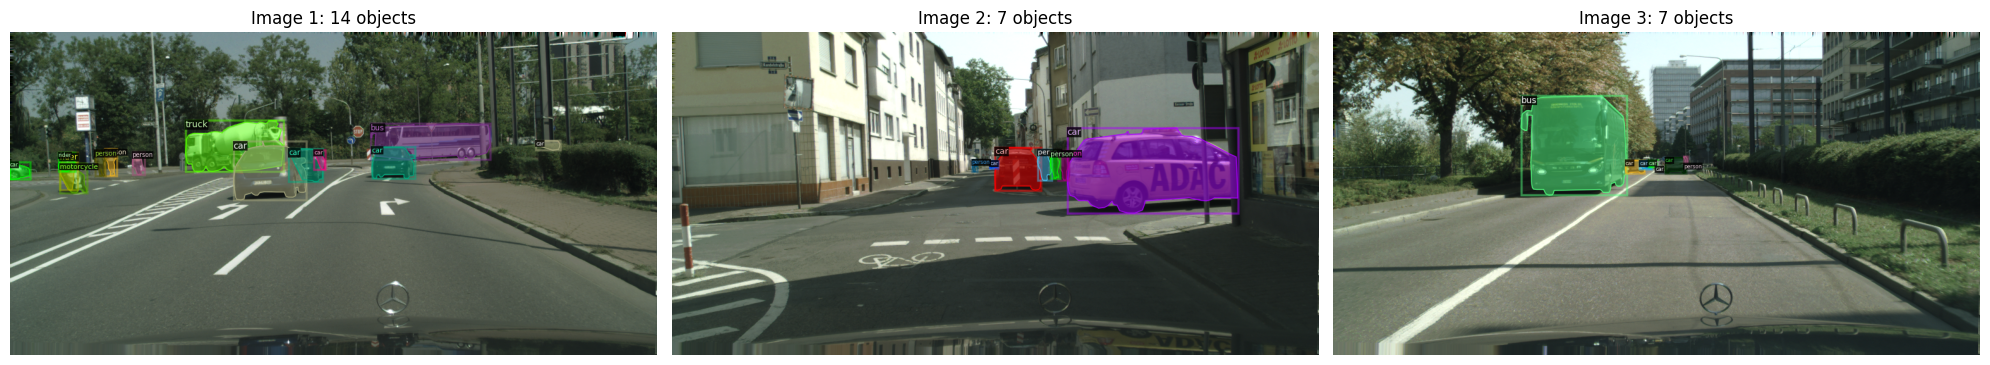


✅ Visualization saved to /home/rachidjunior/VS_Code/INSEG_PRO/outputs/dataset_samples.png


In [8]:
# ============================================
print("Visualizing sample images from dataset...")

# Filter for urban scenes with multiple objects (more interesting)
print("Finding images with diverse annotations...")

diverse_images = []
for d in dataset_dicts:
    num_annotations = len(d['annotations'])
    # Look for images with 5-20 objects (good variety)
    if 5 <= num_annotations <= 20:
        diverse_images.append(d)
    if len(diverse_images) >= 20:  # Get 20 candidates
        break

if not diverse_images:
    diverse_images = dataset_dicts[:10]  # Fallback to first 10

print(f"Found {len(diverse_images)} diverse images")

# Visualize 3 random samples
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

for idx, ax in enumerate(axes):
    # Pick random image
    d = random.choice(diverse_images)
    
    # Load image
    img = cv2.imread(d["file_name"])
    
    if img is None:
        print(f"⚠️  Warning: Could not load {d['file_name']}")
        continue
    
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Create visualizer
    visualizer = Visualizer(
        img_rgb, 
        metadata=metadata, 
        scale=0.5,
        instance_mode=ColorMode.IMAGE  # Show colored masks on original image
    )
    
    # Draw annotations
    out = visualizer.draw_dataset_dict(d)
    
    # Display
    ax.imshow(out.get_image())
    ax.set_title(f"Image {idx+1}: {len(d['annotations'])} objects", fontsize=12)
    ax.axis('off')
    
    # Print details
    print(f"\nImage {idx+1}: {Path(d['file_name']).name}")
    print(f"  Size: {d['width']}x{d['height']}")
    print(f"  Objects: {len(d['annotations'])}")
    
    # Count objects by class
    class_counts = {}
    for ann in d['annotations']:
        class_name = metadata.thing_classes[ann['category_id']]
        class_counts[class_name] = class_counts.get(class_name, 0) + 1
    
    print(f"  Classes: {dict(class_counts)}")

plt.tight_layout()

# Save visualization
output_dir = PROJECT_ROOT / "outputs"
output_dir.mkdir(exist_ok=True)

output_path = output_dir / 'dataset_samples.png'
plt.savefig(output_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ Visualization saved to {output_path}")

### STATISTICS

DATASET STATISTICS

📊 Overall Statistics:
  Total images: 492
  Total instances: 10180
  Average instances per image: 20.69

📐 Image Dimensions:
  Most common size: (2048, 1024)
  Width range: 2048 - 2048
  Height range: 1024 - 1024

🏷️  Class Distribution:
Class           Count      Percentage   Bar
------------------------------------------------------------
car             4667        45.84%     ██████████████████████
person          3419        33.59%     ████████████████
bicycle         1175        11.54%     █████
rider           556          5.46%     ██
motorcycle      149          1.46%     
bus             98           0.96%     
truck           93           0.91%     
train           23           0.23%     

📏 Instance Size Analysis:
Class           Count    Min Area     Avg Area     Max Area    
------------------------------------------------------------
person          3419     24           7916         192198      
rider           556      65           8539         12825

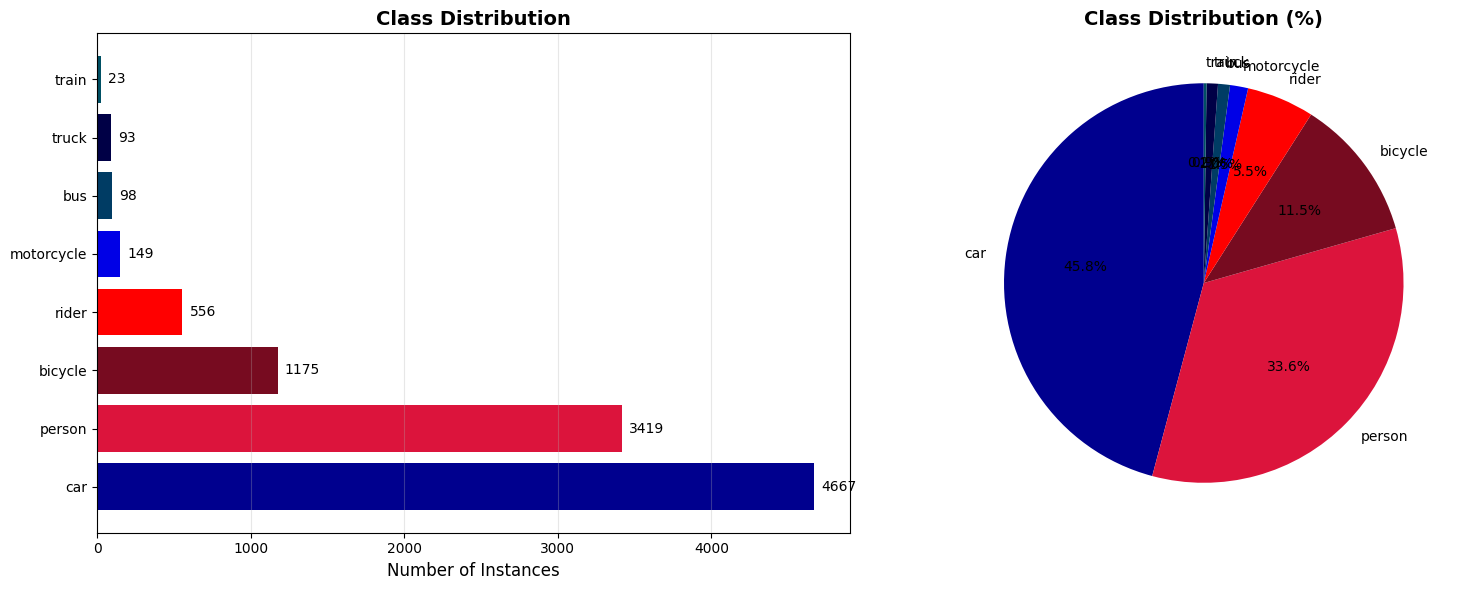


✅ Statistics chart saved to /home/rachidjunior/VS_Code/INSEG_PRO/outputs/dataset_statistics.png

💡 Key Insights:
  • Most common class: car (4667 instances)
  • Least common class: train (23 instances)
  • Class imbalance ratio: 202.9:1
    ⚠️  High imbalance! Consider class weighting during training.
  • Average object size: 14682 pixels² (0.70% of image)


In [9]:
# ============================================

from collections import Counter

print("="*60)
print("DATASET STATISTICS")
print("="*60)

# Basic stats
total_images = len(dataset_dicts)
total_annotations = sum(len(d['annotations']) for d in dataset_dicts)
avg_annotations = total_annotations / total_images if total_images > 0 else 0

print(f"\n📊 Overall Statistics:")
print(f"  Total images: {total_images}")
print(f"  Total instances: {total_annotations}")
print(f"  Average instances per image: {avg_annotations:.2f}")

# Image size analysis
widths = [d['width'] for d in dataset_dicts]
heights = [d['height'] for d in dataset_dicts]

print(f"\n📐 Image Dimensions:")
print(f"  Most common size: {Counter(zip(widths, heights)).most_common(1)[0][0]}")
print(f"  Width range: {min(widths)} - {max(widths)}")
print(f"  Height range: {min(heights)} - {max(heights)}")

# Class distribution
category_counts = Counter()
for d in dataset_dicts:
    for ann in d['annotations']:
        category_counts[ann['category_id']] += 1

print(f"\n🏷️  Class Distribution:")
print("="*60)
print(f"{'Class':<15} {'Count':<10} {'Percentage':<12} {'Bar'}")
print("-"*60)

for cat_id, count in category_counts.most_common():
    cat_name = metadata.thing_classes[cat_id]
    percentage = (count / total_annotations) * 100
    bar_length = int(percentage / 2)  # Scale for display
    bar = "█" * bar_length
    
    print(f"{cat_name:<15} {count:<10} {percentage:>6.2f}%     {bar}")

# Instance size analysis (using area)
print(f"\n📏 Instance Size Analysis:")

areas_by_class = {cls: [] for cls in metadata.thing_classes}

for d in dataset_dicts:
    for ann in d['annotations']:
        cat_name = metadata.thing_classes[ann['category_id']]
        if 'area' in ann:
            areas_by_class[cat_name].append(ann['area'])

print(f"{'Class':<15} {'Count':<8} {'Min Area':<12} {'Avg Area':<12} {'Max Area':<12}")
print("-"*60)

for cat_name in metadata.thing_classes:
    areas = areas_by_class[cat_name]
    if areas:
        min_area = min(areas)
        avg_area = np.mean(areas)
        max_area = max(areas)
        print(f"{cat_name:<15} {len(areas):<8} {min_area:<12.0f} {avg_area:<12.0f} {max_area:<12.0f}")
    else:
        print(f"{cat_name:<15} {'0':<8} {'-':<12} {'-':<12} {'-':<12}")

# Objects per image distribution
print(f"\n📈 Objects per Image Distribution:")

objects_per_image = [len(d['annotations']) for d in dataset_dicts]
obj_distribution = Counter(objects_per_image)

print(f"  Min objects: {min(objects_per_image)}")
print(f"  Max objects: {max(objects_per_image)}")
print(f"  Median objects: {np.median(objects_per_image):.1f}")
print(f"  Std deviation: {np.std(objects_per_image):.2f}")

# Show histogram
print(f"\n  Histogram (objects per image):")
bins = [0, 5, 10, 15, 20, 25, 30, 1000]
labels = ['0-4', '5-9', '10-14', '15-19', '20-24', '25-29', '30+']

for i, (low, high) in enumerate(zip(bins[:-1], bins[1:])):
    count = sum(1 for x in objects_per_image if low <= x < high)
    percentage = (count / total_images) * 100
    bar_length = int(percentage / 2)
    bar = "█" * bar_length
    print(f"    {labels[i]:<8}: {count:>4} ({percentage:>5.1f}%)  {bar}")

# Visualize class distribution
print(f"\n📊 Creating class distribution chart...")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart of class counts
classes = [metadata.thing_classes[cat_id] for cat_id, _ in category_counts.most_common()]
counts = [count for _, count in category_counts.most_common()]
colors = [np.array(metadata.thing_colors[metadata.thing_classes.index(cls)])/255.0 for cls in classes]

ax1.barh(classes, counts, color=colors)
ax1.set_xlabel('Number of Instances', fontsize=12)
ax1.set_title('Class Distribution', fontsize=14, fontweight='bold')
ax1.grid(axis='x', alpha=0.3)

# Add count labels
for i, (cls, count) in enumerate(zip(classes, counts)):
    ax1.text(count + max(counts)*0.01, i, f'{count}', 
             va='center', fontsize=10)

# Pie chart of class percentages
ax2.pie(counts, labels=classes, colors=colors, autopct='%1.1f%%', 
        startangle=90, textprops={'fontsize': 10})
ax2.set_title('Class Distribution (%)', fontsize=14, fontweight='bold')

plt.tight_layout()

# Save
stats_path = output_dir / 'dataset_statistics.png'
plt.savefig(stats_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ Statistics chart saved to {stats_path}")

# Summary insights
print(f"\n💡 Key Insights:")
print("="*60)

# Most common class
most_common_class = metadata.thing_classes[category_counts.most_common(1)[0][0]]
print(f"  • Most common class: {most_common_class} ({category_counts.most_common(1)[0][1]} instances)")

# Least common class
least_common_class = metadata.thing_classes[category_counts.most_common()[-1][0]]
print(f"  • Least common class: {least_common_class} ({category_counts.most_common()[-1][1]} instances)")

# Class imbalance ratio
max_count = category_counts.most_common(1)[0][1]
min_count = category_counts.most_common()[-1][1]
imbalance_ratio = max_count / min_count if min_count > 0 else float('inf')
print(f"  • Class imbalance ratio: {imbalance_ratio:.1f}:1")

if imbalance_ratio > 10:
    print(f"    ⚠️  High imbalance! Consider class weighting during training.")
else:
    print(f"    ✅ Reasonable balance across classes.")

# Average object size
all_areas = []
for d in dataset_dicts:
    for ann in d['annotations']:
        if 'area' in ann:
            all_areas.append(ann['area'])

if all_areas:
    avg_area = np.mean(all_areas)
    # Cityscapes images are typically 2048x1024 = 2,097,152 pixels
    img_area = 2048 * 1024
    relative_size = (avg_area / img_area) * 100
    print(f"  • Average object size: {avg_area:.0f} pixels² ({relative_size:.2f}% of image)")

print("="*60)